#### Search Algorithms

Search Algorithms
- AStar* Algorithm (optalgotools)
- Beam Search Algorithm
- Kruskal


#### AStar* Algorithm

A* Search Algorithm using optalgotools library  finds the shortest route on a geospatial network using a heuristic guided approach. It uses a pathfinder (A_Star) from graph search. It incorporates the Haversine distance heuristic to calculate the great-circle distance between the current node and the destination. It utilizes node and solution wrapper classes to keep track of spatial coordinated, path costs, and metrics like elapsed processing time, memory footprint and explored nodes.

In [6]:
!pip install osmnx optalgotools >/dev/null

In [11]:
# Import necessary libraries for geospatial data, algorithms, search, and plotting
import osmnx
from optalgotools.routing import (
    astar_heuristic, cost, draw_route, get_child, randomized_search)
from optalgotools.structures import Node, Solution
from optalgotools.algorithms.graph_search import A_Star
from optalgotools.utilities import haversine_distance

from itertools import islice
from sys import getsizeof
from time import process_time

import heapq

import numpy as np
import matplotlib.pyplot as plt

In [10]:
center = (40.766876, -73.979076)
source_point = (40.767686, -73.978591)
destination_point = (40.758815, -73.998772)
reference = (40.766876, -73.979076)

# Create the spatial graph from the center point
G = osmnx.graph_from_point(reference, dist=300, simplify=True)

# Get the ID of the nearest node to the source and destination coordinate pairs
source_id = osmnx.distance.nearest_nodes(G, source_point[1], source_point[0])
destination_id = osmnx.distance.nearest_nodes(G, destination_point[1], destination_point[0])

# Wrap IDs into Node objects for compatibility with the optalgotools library
source = Node(graph=G, osmid=source_id)
destination = Node(graph=G, osmid=destination_id)

# Run the A* algorithm using the custom haversine distance heuristic
soln = A_Star(G, source, destination, astar_heuristic, heuristic_kwargs={'measuring_dist': haversine_distance})
route = soln.result

# Output metrics including total route cost, runtime, space usage, and explored nodes count
print(f'Cost: {cost(G,route)} m')
print(f'Processing time: {soln.time} seconds')
print(f'Space required: {soln.space} bytes')
print(f'Explored nodes: {soln.explored}')

Cost: 745.8841 m
Processing time: 0.0023991779999992247 seconds
Space required: 2264 bytes
Explored nodes: 50


#### Beam Search

Beam Search Algorithm performs a heuristic pathfinding search that limits memory exploration by maintaining only the top optimal pathways at any given step with the beam width. One method generated up to n child nodes for each part in the current beam, allowing algorithm to branch out forward. The search algorithm initializes k-randomized paths from the source to the target. It expands paths and keeps track of visited routes inside a visited set. Employs heapq smallest to prune the active candidate pool, keeping only k most efficient routed at each iteration step.




Set point of interest

In [ ]:
center = (40.766876, -73.979076)
source_point = (40.767686, -73.978591)
destination_point = (40.758815, -73.998772)
reference = (40.766876, -73.979076)

# create the graph
G = osmnx.graph_from_point(reference, dist=300, simplify=True)

# get the id of the nearest node to the source and destination points
source_id = osmnx.distance.nearest_nodes(G, source_point[1], source_point[0])
destination_id = osmnx.distance.nearest_nodes(G, destination_point[1], destination_point[0])

# convert source and destination nodes to node
source = Node(graph=G, osmid=source_id)
destination = Node(graph=G, osmid=destination_id)

Beam Search Algorithm

In [ ]:
def get_beam(G, beam, n=20):
    new_beam = []
    for route in beam:
        neighbors = list(islice(get_child(G, route), n))
        new_beam.extend(neighbors)
    return new_beam

In [12]:
def beam_search(G, source, destimation, k=10, n=20):
    """
    Executes a Beam Search algorithm on a spatial graph G to find an optimal path.

    Parameters:
    G (networkx.MultiDiGraph): The spatial graph environment.
    source (Node): The starting node object containing the osmid.
    destination (Node): The target node object containing the osmid.
    k (int, optional): The beam width (number of top paths to maintain). Defaults to 10.
    n (int, optional): The max number of child nodes/routes to generate per path. Defaults to 20.

    Returns:
    Solution: A solution object containing the optimal path, execution time, peak space required, and historical path cost matrix.
    """
    # 1. Start execution timing for benchmarking
    start_time = process_time()
    seen = set()
    costs = []

    # 2. Initialize the search space with k randomized paths from source to destination
    beam = [randomized_search(G, source.osmid, destination.osmid)
            for _ in range(k)]

    # 3. Track evaluated paths in a set to avoid processing duplicate routes
    for route in beam:
        seen.add(tuple(route))

    pool = []
    # 4. Expand initial beam paths by finding their neighboring routes
    children = get_beam(G, beam, n)
    costs.append([cost(G, r) for r in beam])

    # 5. Filter out duplicate pathways and populate our active candidates pool
    for child in children:
        if tuple(child) in seen:
            continue
        else:
            pool.append(child)
            seen.add(tuple(child))
    pool += beam
    space_required = getsizeof(pool)
    last_beam = None

    # 6. Begin iterative local search optimization loop
    while beam != last_beam:
        last_beam = beam
        # Keep only the top k paths with the lowest physical cost
        beam = heapq.nsmallest(k, pool, key=lambda x: cost(G, x))

        for route in beam:
            seen.add(tuple(route))

        pool = []
        # Generate new neighboring candidates from the current k-best paths
        children = get_beam(G, beam, n)
        costs.append([cost(G, r) for r in beam])
        for child in children:
            if tuple(child) in seen:
                continue
            else:
                pool.append(child)
                seen.add(tuple(child))
        pool += beam
        # Measure maximum memory space consumed by the search pool
        space_required = (getsizeof(pool) if getsizeof(pool) > space_required else space_required)

    # 7. Select the ultimate best route from our stable optimized beam
    route = min(beam, key=lambda x: cost(G, x))
    end_time = process_time()

    return Solution(
        route, end_time - start_time, space_required, np.rot90(costs))

Find the shortest route

Cost: 569.2878 m
Processing time: 65.79103791899979 seconds
Space required: 1656 bytes


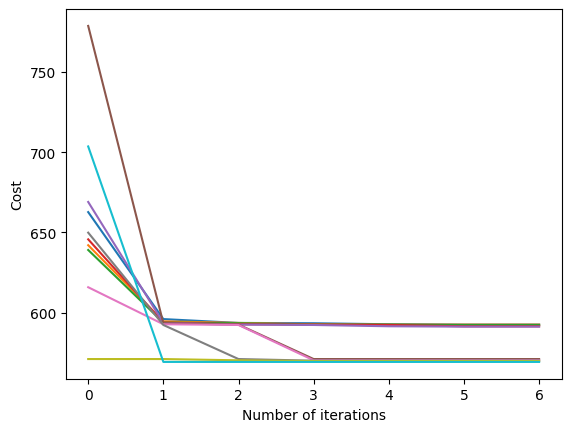

In [ ]:
solution = beam_search(G, source, destination, k=10, n=20)
route = solution.result
print(f'Cost: {cost(G,route)} m')
print(f'Processing time: {solution.time} seconds')
print(f'Space required: {solution.space} bytes')
for c in solution.explored:
    plt.plot(c)
plt.xticks(list(range(len(solution.explored[0]))))
plt.xlabel('Number of iterations')
plt.ylabel('Cost')
plt.show()

#### Kruskal Algorithm

Kruskal Algorithm  computes the Minimum Spanning Tree (MST) of a connected undirected graph, linking all nodes with minimum possible total edge weight and without any cycles. Sorts all the edges based on their IDs, performs iterative tree assembly, prevents cycles and checks if spanning tree is fully connected for early termination.

Create a graph

In [ ]:
from __future__ import annotations
from typing import *
from typing_extensions import Protocol
T = TypeVar('T')

class Comparable(Protocol):
    def __eq__(self, other: Any) -> bool: ...
    def __lt__(self: T, other: T) -> bool: ...
    def __gt__(self: T, other: T) -> bool:
        return (not self < other) and  self == other
    def __le__(self: T, other: T) -> bool:
        return self < other or self == other
    def __ge__(self: T, other: T) -> bool:
        return not self < other

In [1]:
def Kruskal(G, attr='length'):
    """
    Computes the Minimum Spanning Tree (MST) of a given graph using Kruskal's Algorithm.

    Parameters:
    G (networkx.Graph / networkx.MultiGraph): The input graph on which to construct the MST.
    attr (str, optional): The edge attribute representing weight or distance. Defaults to 'length'.

    Returns:
    networkx.Graph: An undirected simple Graph representing the Minimum Spanning Tree.
    """
    # 1. Sort all edges based on their ID attribute (falling back to 1 if missing) to ensure a deterministic order
    edges = sorted(G.edges(data=True), key=lambda t: str(t[2].get('osmid', 1)))

    # 2. Initialize an empty undirected Graph with the same nodes as the input graph
    mst = nx.Graph()
    mst.add_nodes_from(G)

    # 3. Iterate through sorted edges and try to add each to the spanning tree
    for edge in edges:
        # Ensure length attribute is converted to an integer
        edge[2]['length'] = int(edge[2]['length'])
        mst.add_edges_from([edge])

        try:
            # 4. Use cycle detection to see if adding this edge closes a cycle
            nx.find_cycle(mst)
            mst.remove_edge(edge[0], edge[1])
        except nx.NetworkXNoCycle:
            # 5. If no cycle is formed, keep the edge. Check if the spanning tree is now fully connected
            if nx.is_connected(mst):
                break
            continue
    return mst

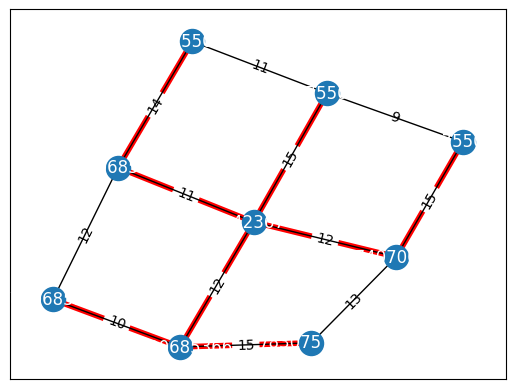

In [ ]:
G = nx.Graph()
G.add_nodes_from([42423674, 7830685366, 7830685378, 1740700804, 4347550033, 7830685373, 4347550047, 4347550043, 7830757210])

edges = [
    (42423674, 7830685366, {'length': 12}), (42423674, 7830685378, {'length': 11}), (7830685378, 42423674, {'length': 11}), (42423674, 1740700804, {'length': 12}), (1740700804, 42423674, {'length': 12}), (42423674, 4347550047, {'length': 15}), (4347550047, 42423674, {'length': 15}),  (7830685373, 7830685366, {'length': 10}), (7830685378, 4347550033, {'length': 14}), (7830685373, 7830685378, {'length': 12}), (7830685378, 7830685373, {'length': 12}),  (7830685366, 7830757210, {'length': 15}), (7830757210, 7830685366, {'length': 15}),  (7830685366, 7830685373, {'length': 10}), (4347550043, 4347550047, {'length': 9}), (4347550047, 4347550043, {'length': 9}), (4347550033, 4347550047, {'length': 11}), (4347550047, 4347550033, {'length': 11}), (1740700804, 4347550043, {'length': 15}), (4347550043, 1740700804, {'length': 15}), (1740700804, 7830757210, {'length': 13}), (7830757210, 1740700804, {'length': 13})
]

G.add_edges_from(edges)
pos = nx.spring_layout(G, seed=30)
MST = Kruskal(G).edges
labels = nx.get_edge_attributes(G, 'length')
nx.draw_networkx_edges(G, pos, list(MST), width=4, edge_color='red')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)
nx.draw_networkx(G, pos, with_labels=True, font_color='white')
plt.show()

Create a second graph

In [ ]:
# Set point of interest
center = (40.766876, -73.979076)
source_point = (40.767686, -73.978591)
destination_point = (40.758815, -73.998772)
reference = (40.766876, -73.979076)
# create the graph
G = osmnx.graph_from_point(reference, dist=25, simplify=True)
G.edges

OutMultiEdgeView([(42423674, 4347550047, 0), (42423674, 7830685378, 0), (42423674, 1740700804, 0), (42423674, 7830685366, 0), (1740700804, 42423674, 0), (1740700804, 4347550043, 0), (1740700804, 7830757210, 0), (4347550033, 7830685378, 0), (4347550033, 4347550047, 0), (4347550043, 4347550047, 0), (4347550043, 1740700804, 0), (4347550047, 42423674, 0), (4347550047, 4347550033, 0), (4347550047, 4347550043, 0), (7830685366, 7830757210, 0), (7830685366, 7830685373, 0), (7830685373, 7830685378, 0), (7830685373, 7830685366, 0), (7830685378, 42423674, 0), (7830685378, 7830685373, 0), (7830685378, 4347550033, 0), (7830757210, 7830685366, 0), (7830757210, 1740700804, 0)])

In [ ]:
pos = nx.spring_layout(G, seed=30)

EdgeView([(42423674, 7830685366), (42423674, 7830685378), (42423674, 1740700804), (42423674, 4347550047), (4347550033, 7830685378), (4347550043, 4347550047), (7830685366, 7830685373), (7830685366, 7830757210)])

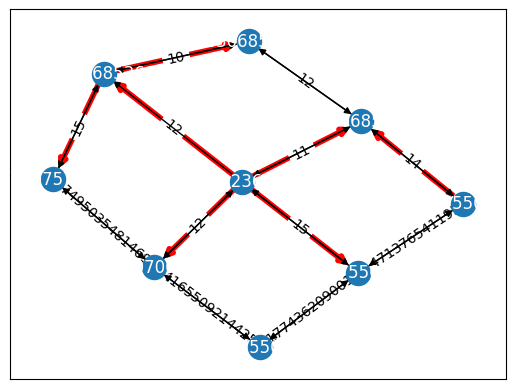

In [ ]:
MST = Kruskal(G).edges
labels = nx.get_edge_attributes(G, 'length')
nx.draw_networkx_edges(G, pos, list(MST), width=4, edge_color='red')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)
nx.draw_networkx(G, pos, with_labels=True, font_color='white')
MST